In [15]:
import io
import pandas as pd
import numpy as np
import plotly.express as px
import plotly.graph_objects as go

pd.set_option("display.max_rows", None)
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 1200)

CSV_DATA = """year,decade,award_era,awarded,player,country,modern_country,confederation,club,club_league,position,age_at_win,season_goals,season_assists,winner_points,runner_up,runner_up_country,third_place,third_place_country,key_achievement,general_position,goal_contributions
1956,1950s,European Players Only,True,Stanley Matthews,England,England,UEFA,Blackpool,England (First Division),Forward / Winger,41.0,3.0,12.0,47.0,Alfredo Di Stéfano,Spain,Raymond Kopa,France,FA Cup Finalist,Forward,15.0
1957,1950s,European Players Only,True,Alfredo Di Stéfano,Spain,Spain,UEFA,Real Madrid,Spain (La Liga),Forward,31.0,43.0,10.0,72.0,Billy Wright,England,Duncan Edwards / Raymond Kopa,England / France,European Cup & La Liga,Forward,53.0
1958,1950s,European Players Only,True,Raymond Kopa,France,France,UEFA,Real Madrid,Spain (La Liga),Attacking Midfielder / Forward,27.0,11.0,15.0,71.0,Helmut Rahn,West Germany,Just Fontaine,France,European Cup & 3rd Place World Cup,Midfielder,26.0
1959,1950s,European Players Only,True,Alfredo Di Stéfano,Spain,Spain,UEFA,Real Madrid,Spain (La Liga),Forward,33.0,34.0,11.0,80.0,Raymond Kopa,France,John Charles,Wales,European Cup,Forward,45.0
1960,1960s,European Players Only,True,Luis Suárez,Spain,Spain,UEFA,Barcelona,Spain (La Liga),Midfielder,25.0,14.0,18.0,54.0,Ferenc Puskás,Hungary,Uwe Seeler,West Germany,La Liga & Inter-Cities Fairs Cup,Midfielder,32.0
1961,1960s,European Players Only,True,Omar Sívori,Italy,Italy,UEFA,Juventus,Italy (Serie A),Forward,26.0,28.0,12.0,46.0,Luis Suárez,Spain,Johnny Haynes,England,Serie A,Forward,40.0
1962,1960s,European Players Only,True,Josef Masopust,Czechoslovakia,Czech Republic,UEFA,Dukla Prague,Czechoslovakia (1. Liga),Midfielder,31.0,12.0,14.0,65.0,Eusébio,Portugal,Karl-Heinz Schnellinger,West Germany,World Cup Finalist & Czechoslovak First League,Midfielder,26.0
1963,1960s,European Players Only,True,Lev Yashin,Soviet Union,Soviet Union,UEFA,Dynamo Moscow,USSR (Top League),Goalkeeper,34.0,0.0,0.0,73.0,Gianni Rivera,Italy,Jimmy Greaves,England,Soviet Top League,Goalkeeper,0.0
1964,1960s,European Players Only,True,Denis Law,Scotland,Scotland,UEFA,Manchester United,England (First Division),Forward,24.0,46.0,9.0,61.0,Luis Suárez,Spain,Amancio,Spain,46 Goals in Season,Forward,55.0
1965,1960s,European Players Only,True,Eusébio,Portugal,Portugal,UEFA,Benfica,Portugal (Primeira Divisão),Forward,23.0,48.0,11.0,67.0,Giacinto Facchetti,Italy,Luis Suárez,Spain,Primeira Divisão & European Cup Finalist,Forward,59.0
1966,1960s,European Players Only,True,Bobby Charlton,England,England,UEFA,Manchester United,England (First Division),Attacking Midfielder,29.0,18.0,15.0,81.0,Eusébio,Portugal,Franz Beckenbauer,West Germany,1966 FIFA World Cup Winner,Midfielder,33.0
1967,1960s,European Players Only,True,Flórián Albert,Hungary,Hungary,UEFA,Ferencváros,Hungary (NB I),Forward,26.0,28.0,10.0,68.0,Bobby Charlton,England,Jimmy Johnstone,Scotland,Hungarian League,Forward,38.0
1968,1960s,European Players Only,True,George Best,Northern Ireland,Northern Ireland,UEFA,Manchester United,England (First Division),Winger / Forward,22.0,32.0,14.0,61.0,Bobby Charlton,England,Dragan Džajić,Yugoslavia,European Cup,Forward,46.0
1969,1960s,European Players Only,True,Gianni Rivera,Italy,Italy,UEFA,AC Milan,Italy (Serie A),Attacking Midfielder,26.0,11.0,19.0,83.0,Luigi Riva,Italy,Gerd Müller,West Germany,European Cup & Intercontinental Cup,Midfielder,30.0
1970,1970s,European Players Only,True,Gerd Müller,West Germany,Germany,UEFA,Bayern Munich,Germany (Bundesliga),Forward,25.0,42.0,6.0,77.0,Bobby Moore,England,Luigi Riva,Italy,1970 World Cup Golden Boot (10 goals),Forward,48.0
1971,1970s,European Players Only,True,Johan Cruyff,Netherlands,Netherlands,UEFA,Ajax,Netherlands (Eredivisie),Forward / Midfielder,24.0,27.0,21.0,116.0,Sandro Mazzola,Italy,George Best,Northern Ireland,European Cup,Forward,48.0
1972,1970s,European Players Only,True,Franz Beckenbauer,West Germany,Germany,UEFA,Bayern Munich,Germany (Bundesliga),Defender / Sweeper,27.0,6.0,11.0,81.0,Gerd Müller / Günter Netzer,West Germany,,,Euro 1972 & Bundesliga,Defender,17.0
1973,1970s,European Players Only,True,Johan Cruyff,Netherlands,Netherlands,UEFA,Ajax / Barcelona,Spain (La Liga),Forward / Midfielder,26.0,24.0,22.0,96.0,Dino Zoff,Italy,Gerd Müller,West Germany,European Cup & La Liga,Forward,46.0
1974,1970s,European Players Only,True,Johan Cruyff,Netherlands,Netherlands,UEFA,Barcelona,Spain (La Liga),Forward / Midfielder,27.0,19.0,20.0,116.0,Franz Beckenbauer,West Germany,Kazimierz Deyna,Poland,La Liga & World Cup Finalist,Forward,39.0
1975,1970s,European Players Only,True,Oleg Blokhin,Soviet Union,Soviet Union,UEFA,Dynamo Kyiv,USSR (Top League),Forward,23.0,25.0,9.0,122.0,Franz Beckenbauer,West Germany,Johan Cruyff,Netherlands,European Cup Winners' Cup & UEFA Super Cup,Forward,34.0
1976,1970s,European Players Only,True,Franz Beckenbauer,West Germany,Germany,UEFA,Bayern Munich,Germany (Bundesliga),Defender / Sweeper,31.0,5.0,10.0,91.0,Rob Rensenbrink,Netherlands,Ivo Viktor,Czechoslovakia,European Cup & Intercontinental Cup,Defender,15.0
1977,1970s,European Players Only,True,Allan Simonsen,Denmark,Denmark,UEFA,Borussia Mönchengladbach,Germany (Bundesliga),Forward,25.0,18.0,12.0,74.0,Kevin Keegan,England,Michel Platini,France,Bundesliga & European Cup Finalist,Forward,30.0
1978,1970s,European Players Only,True,Kevin Keegan,England,England,UEFA,Hamburger SV,Germany (Bundesliga),Forward,27.0,17.0,13.0,87.0,Hans Krankl,Austria,Rob Rensenbrink,Netherlands,Bundesliga,Forward,30.0
1979,1970s,European Players Only,True,Kevin Keegan,England,England,UEFA,Hamburger SV,Germany (Bundesliga),Forward,28.0,17.0,14.0,118.0,Karl-Heinz Rummenigge,West Germany,Ruud Krol,Netherlands,Bundesliga,Forward,31.0
1980,1980s,European Players Only,True,Karl-Heinz Rummenigge,West Germany,Germany,UEFA,Bayern Munich,Germany (Bundesliga),Forward,25.0,29.0,11.0,122.0,Bernd Schuster,West Germany,Michel Platini,France,Euro 1980 & Bundesliga,Forward,40.0
1981,1980s,European Players Only,True,Karl-Heinz Rummenigge,West Germany,Germany,UEFA,Bayern Munich,Germany (Bundesliga),Forward,26.0,29.0,10.0,106.0,Paul Breitner,West Germany,Bernd Schuster,West Germany,Bundesliga,Forward,39.0
1982,1980s,European Players Only,True,Paolo Rossi,Italy,Italy,UEFA,Juventus,Italy (Serie A),Forward,26.0,13.0,4.0,115.0,Alain Giresse,France,Zbigniew Boniek,Poland,1982 FIFA World Cup Winner & Golden Boot,Forward,17.0
1983,1980s,European Players Only,True,Michel Platini,France,France,UEFA,Juventus,Italy (Serie A),Attacking Midfielder,28.0,28.0,14.0,110.0,Kenny Dalglish,Scotland,Allan Simonsen,Denmark,Coppa Italia & Serie A Top Scorer,Midfielder,42.0
1984,1980s,European Players Only,True,Michel Platini,France,France,UEFA,Juventus,Italy (Serie A),Attacking Midfielder,29.0,25.0,16.0,128.0,Jean Tigana,France,Preben Elkjær,Denmark,Euro 1984 (9 goals) & Serie A,Midfielder,41.0
1985,1980s,European Players Only,True,Michel Platini,France,France,UEFA,Juventus,Italy (Serie A),Attacking Midfielder,30.0,29.0,15.0,127.0,Preben Elkjær,Denmark,Bernd Schuster,West Germany,European Cup & Intercontinental Cup,Midfielder,44.0
1986,1980s,European Players Only,True,Igor Belanov,Soviet Union,Soviet Union,UEFA,Dynamo Kyiv,USSR (Top League),Forward,26.0,20.0,8.0,84.0,Gary Lineker,England,Emilio Butragueño,Spain,European Cup Winners' Cup & Soviet Top League,Forward,28.0
1987,1980s,European Players Only,True,Ruud Gullit,Netherlands,Netherlands,UEFA,PSV / AC Milan,Italy (Serie A),Midfielder / Forward,25.0,24.0,15.0,106.0,Paulo Futre,Portugal,Emilio Butragueño,Spain,Eredivisie (PSV),Midfielder,39.0
1988,1980s,European Players Only,True,Marco van Basten,Netherlands,Netherlands,UEFA,AC Milan,Italy (Serie A),Forward,24.0,19.0,6.0,129.0,Ruud Gullit,Netherlands,Frank Rijkaard,Netherlands,Euro 1988 & Serie A,Forward,25.0
1989,1980s,European Players Only,True,Marco van Basten,Netherlands,Netherlands,UEFA,AC Milan,Italy (Serie A),Forward,25.0,32.0,8.0,119.0,Franco Baresi,Italy,Frank Rijkaard,Netherlands,European Cup & Intercontinental Cup,Forward,40.0
1990,1990s,European Players Only,True,Lothar Matthäus,West Germany,Germany,UEFA,Inter Milan,Italy (Serie A),Midfielder,29.0,13.0,12.0,137.0,Salvatore Schillaci,Italy,Andreas Brehme,West Germany,1990 FIFA World Cup Winner,Midfielder,25.0
1991,1990s,European Players Only,True,Jean-Pierre Papin,France,France,UEFA,Marseille,France (Ligue 1),Forward,28.0,36.0,7.0,141.0,Dejan Savićević / Darko Pančev / Lothar Matthäus,Yugoslavia / Germany,,,Ligue 1 & European Cup Finalist,Forward,43.0
1992,1990s,European Players Only,True,Marco van Basten,Netherlands,Netherlands,UEFA,AC Milan,Italy (Serie A),Forward,28.0,29.0,9.0,98.0,Hristo Stoichkov,Bulgaria,Dennis Bergkamp,Netherlands,Serie A (Unbeaten),Forward,38.0
1993,1990s,European Players Only,True,Roberto Baggio,Italy,Italy,UEFA,Juventus,Italy (Serie A),Attacking Midfielder / Forward,26.0,30.0,14.0,142.0,Dennis Bergkamp,Netherlands,Eric Cantona,France,UEFA Cup,Midfielder,44.0
1994,1990s,European Players Only,True,Hristo Stoichkov,Bulgaria,Bulgaria,UEFA,Barcelona,Spain (La Liga),Forward,28.0,24.0,11.0,210.0,Roberto Baggio,Italy,Paolo Maldini,Italy,La Liga & 1994 World Cup Golden Boot,Forward,35.0
1995,1990s,European Club Players,True,George Weah,Liberia,Liberia,CAF,Paris Saint-Germain / AC Milan,Italy (Serie A),Forward,29.0,18.0,9.0,144.0,Jürgen Klinsmann,Germany,Jari Litmanen,Finland,Coupe de France & Champions League Top Scorer,Forward,27.0
1996,1990s,European Club Players,True,Matthias Sammer,Germany,Germany,UEFA,Borussia Dortmund,Germany (Bundesliga),Defender / Sweeper,29.0,5.0,6.0,144.0,Ronaldo,Brazil,Alan Shearer,England,Euro 1996 & Bundesliga,Defender,11.0
1997,1990s,European Club Players,True,Ronaldo,Brazil,Brazil,CONMEBOL,Barcelona / Inter Milan,Italy (Serie A),Forward,21.0,47.0,12.0,222.0,Predrag Mijatović,Yugoslavia,Zinédine Zidane,France,UEFA Cup Winners' Cup & Copa América 1997,Forward,59.0
1998,1990s,European Club Players,True,Zinédine Zidane,France,France,UEFA,Juventus,Italy (Serie A),Attacking Midfielder,26.0,11.0,16.0,244.0,Davor Šuker,Croatia,Ronaldo,Brazil,1998 FIFA World Cup Winner & Serie A,Midfielder,27.0
1999,1990s,European Club Players,True,Rivaldo,Brazil,Brazil,CONMEBOL,Barcelona,Spain (La Liga),Attacking Midfielder / Forward,27.0,29.0,15.0,219.0,David Beckham,England,Andriy Shevchenko,Ukraine,La Liga & Copa América 1999,Midfielder,44.0
2000,2000s,European Club Players,True,Luís Figo,Portugal,Portugal,UEFA,Barcelona / Real Madrid,Spain (La Liga),Winger / Midfielder,28.0,14.0,22.0,197.0,Zinédine Zidane,France,Andriy Shevchenko,Ukraine,Euro 2000 Semi-Finalist,Forward,36.0
2001,2000s,European Club Players,True,Michael Owen,England,England,UEFA,Liverpool,England (Premier League),Forward,22.0,24.0,7.0,176.0,Raúl,Spain,Oliver Kahn,Germany,"UEFA Cup, FA Cup & League Cup",Forward,31.0
2002,2000s,European Club Players,True,Ronaldo,Brazil,Brazil,CONMEBOL,Inter Milan / Real Madrid,Spain (La Liga),Forward,26.0,15.0,3.0,169.0,Roberto Carlos,Brazil,Oliver Kahn,Germany,2002 FIFA World Cup Winner (8 goals),Forward,18.0
2003,2000s,European Club Players,True,Pavel Nedvěd,Czech Republic,Czech Republic,UEFA,Juventus,Italy (Serie A),Midfielder,31.0,14.0,17.0,190.0,Thierry Henry,France,Paolo Maldini,Italy,Serie A & Champions League Finalist,Midfielder,31.0
2004,2000s,European Club Players,True,Andriy Shevchenko,Ukraine,Ukraine,UEFA,AC Milan,Italy (Serie A),Forward,28.0,29.0,5.0,175.0,Deco,Portugal,Ronaldinho,Brazil,Serie A & Capocannoniere,Forward,34.0
2005,2000s,European Club Players,True,Ronaldinho,Brazil,Brazil,CONMEBOL,Barcelona,Spain (La Liga),Attacking Midfielder / Winger,25.0,13.0,16.0,225.0,Frank Lampard,England,Steven Gerrard,England,La Liga & FIFA Confederations Cup,Midfielder,29.0
2006,2000s,European Club Players,True,Fabio Cannavaro,Italy,Italy,UEFA,Juventus / Real Madrid,Spain (La Liga),Center-Back,33.0,4.0,1.0,173.0,Gianluigi Buffon,Italy,Thierry Henry,France,2006 FIFA World Cup Winner,Defender,5.0
2007,2000s,Global Era,True,Kaká,Brazil,Brazil,CONMEBOL,AC Milan,Italy (Serie A),Attacking Midfielder,25.0,18.0,11.0,444.0,Cristiano Ronaldo,Portugal,Lionel Messi,Argentina,Champions League & FIFA Club World Cup,Midfielder,29.0
2008,2000s,Global Era,True,Cristiano Ronaldo,Portugal,Portugal,UEFA,Manchester United,England (Premier League),Winger / Forward,23.0,42.0,8.0,446.0,Lionel Messi,Argentina,Fernando Torres,Spain,"Champions League, Premier League & European Golden Shoe",Forward,50.0
2009,2000s,Global Era,True,Lionel Messi,Argentina,Argentina,CONMEBOL,Barcelona,Spain (La Liga),Forward / Winger,22.0,38.0,18.0,473.0,Cristiano Ronaldo,Portugal,Xavi,Spain,"Continental Treble (Champions League, La Liga, Copa del Rey)",Forward,56.0
2010,2010s,FIFA Ballon d'Or,True,Lionel Messi,Argentina,Argentina,CONMEBOL,Barcelona,Spain (La Liga),Forward,23.0,47.0,11.0,2265.0,Andrés Iniesta,Spain,Xavi,Spain,La Liga & European Golden Shoe,Forward,58.0
2011,2010s,FIFA Ballon d'Or,True,Lionel Messi,Argentina,Argentina,CONMEBOL,Barcelona,Spain (La Liga),Forward,24.0,53.0,24.0,4788.0,Cristiano Ronaldo,Portugal,Xavi,Spain,Champions League & La Liga,Forward,77.0
2012,2010s,FIFA Ballon d'Or,True,Lionel Messi,Argentina,Argentina,CONMEBOL,Barcelona,Spain (La Liga),Forward,25.0,73.0,29.0,4160.0,Cristiano Ronaldo,Portugal,Andrés Iniesta,Spain,Record 91 Calendar Year Goals & Golden Shoe,Forward,102.0
2013,2010s,FIFA Ballon d'Or,True,Cristiano Ronaldo,Portugal,Portugal,UEFA,Real Madrid,Spain (La Liga),Winger / Forward,28.0,55.0,13.0,1365.0,Lionel Messi,Argentina,Franck Ribéry,France,69 Calendar Year Goals & World Cup Play-off,Forward,68.0
2014,2010s,FIFA Ballon d'Or,True,Cristiano Ronaldo,Portugal,Portugal,UEFA,Real Madrid,Spain (La Liga),Winger / Forward,29.0,51.0,17.0,3766.0,Lionel Messi,Argentina,Manuel Neuer,Germany,Champions League (La Décima) & Golden Shoe,Forward,68.0
2015,2010s,FIFA Ballon d'Or,True,Lionel Messi,Argentina,Argentina,CONMEBOL,Barcelona,Spain (La Liga),Forward / Winger,28.0,58.0,27.0,4133.0,Cristiano Ronaldo,Portugal,Neymar,Brazil,"Continental Treble (Champions League, La Liga, Copa del Rey)",Forward,85.0
2016,2010s,France Football Return,True,Cristiano Ronaldo,Portugal,Portugal,UEFA,Real Madrid,Spain (La Liga),Forward / Winger,31.0,51.0,15.0,745.0,Lionel Messi,Argentina,Antoine Griezmann,France,Champions League & Euro 2016,Forward,66.0
2017,2010s,France Football Return,True,Cristiano Ronaldo,Portugal,Portugal,UEFA,Real Madrid,Spain (La Liga),Forward,32.0,42.0,12.0,946.0,Lionel Messi,Argentina,Neymar,Brazil,Champions League & La Liga,Forward,54.0
2018,2010s,France Football Return,True,Luka Modrić,Croatia,Croatia,UEFA,Real Madrid,Spain (La Liga),Midfielder,33.0,2.0,8.0,753.0,Cristiano Ronaldo,Portugal,Antoine Griezmann,France,Champions League & World Cup Finalist (Golden Ball),Midfielder,10.0
2019,2010s,France Football Return,True,Lionel Messi,Argentina,Argentina,CONMEBOL,Barcelona,Spain (La Liga),Forward,32.0,51.0,22.0,686.0,Virgil van Dijk,Netherlands,Cristiano Ronaldo,Portugal,La Liga & European Golden Shoe,Forward,73.0
2020,2020s,Cancelled (COVID-19),False,,,,,,,,,,,,,,,,Cancelled due to COVID-19 pandemic,,
2021,2020s,France Football Return,True,Lionel Messi,Argentina,Argentina,CONMEBOL,Barcelona / Paris Saint-Germain,France (Ligue 1),Forward,34.0,38.0,14.0,613.0,Robert Lewandowski,Poland,Jorginho,Italy,Copa América 2021,Forward,52.0
2022,2020s,Season-Based Format,True,Karim Benzema,France,France,UEFA,Real Madrid,Spain (La Liga),Forward,34.0,44.0,15.0,549.0,Sadio Mané,Senegal,Kevin De Bruyne,Belgium,Champions League & La Liga,Forward,59.0
2023,2020s,Season-Based Format,True,Lionel Messi,Argentina,Argentina,CONMEBOL,Paris Saint-Germain / Inter Miami,USA (MLS),Forward,36.0,21.0,20.0,462.0,Erling Haaland,Norway,Kylian Mbappé,France,2022 FIFA World Cup Winner (Golden Ball),Forward,41.0
2024,2020s,Season-Based Format (UEFA),True,Rodri,Spain,Spain,UEFA,Manchester City,England (Premier League),Midfielder,28.0,9.0,14.0,1170.0,Vinícius Júnior,Brazil,Jude Bellingham,England,Euro 2024 & Premier League,Midfielder,23.0
"""

df = pd.read_csv(io.StringIO(CSV_DATA))
df["year"] = df["year"].astype(int)

def classify_trophy(ach):
    if pd.isna(ach):
        return "Domestic / Individual Only"
    ach_low = ach.lower()
    if "world cup winner" in ach_low:
        return "World Cup Winner"
    if "euro " in ach_low or "copa américa" in ach_low:
        return "Continental National (Euro/Copa)"
    if "champions league" in ach_low or "european cup" in ach_low:
        if "european cup finalist" not in ach_low and "champions league finalist" not in ach_low and "top scorer" not in ach_low:
            return "Champions League / European Cup"
    return "Domestic / Individual Only"

df_valid = df[df["awarded"] == True].copy()
df_valid["trophy_tier"] = df_valid["key_achievement"].apply(classify_trophy)

display(df_valid[["year", "player", "modern_country", "club", "general_position", "age_at_win", "season_goals", "season_assists", "goal_contributions", "trophy_tier", "key_achievement"]])

,year,player,modern_country,club,general_position,age_at_win,season_goals,season_assists,goal_contributions,trophy_tier,key_achievement
0,1956,Stanley Matthews,England,Blackpool,Forward,41.0,3.0,12.0,15.0,Domestic / Individual Only,FA Cup Finalist
1,1957,Alfredo Di Stéfano,Spain,Real Madrid,Forward,31.0,43.0,10.0,53.0,Champions League / European Cup,European Cup & La Liga
2,1958,Raymond Kopa,France,Real Madrid,Midfielder,27.0,11.0,15.0,26.0,Champions League / European Cup,European Cup & 3rd Place World Cup
3,1959,Alfredo Di Stéfano,Spain,Real Madrid,Forward,33.0,34.0,11.0,45.0,Champions League / European Cup,European Cup
4,1960,Luis Suárez,Spain,Barcelona,Midfielder,25.0,14.0,18.0,32.0,Domestic / Individual Only,La Liga & Inter-Cities Fairs Cup
5,1961,Omar Sívori,Italy,Juventus,Forward,26.0,28.0,12.0,40.0,Domestic / Individual Only,Serie A
6,1962,Josef Masopust,Czech Republic,Dukla Prague,Midfielder,31.0,12.0,14.0,26.0,Domestic / Individual Only,World Cup Finalist & Czechoslovak First League
7,1963,Lev Yashin,Soviet Union,Dynamo Moscow,Goalkeeper,34.0,0.0,0.0,0.0,Domestic / Individual Only,Soviet Top League
8,1964,Denis Law,Scotland,Manchester United,Forward,24.0,46.0,9.0,55.0,Domestic / Individual Only,46 Goals in Season
9,1965,Eusébio,Portugal,Benfica,Forward,23.0,48.0,11.0,59.0,Domestic / Individual Only,Primeira Divisão & European Cup Finalist



==================== CHAMPIONS LEAGUE / EUROPEAN CUP (21 vencedores) ====================


,year,player,club,season_goals,season_assists,goal_contributions,key_achievement
1,1957,Alfredo Di Stéfano,Real Madrid,43.0,10.0,53.0,European Cup & La Liga
2,1958,Raymond Kopa,Real Madrid,11.0,15.0,26.0,European Cup & 3rd Place World Cup
3,1959,Alfredo Di Stéfano,Real Madrid,34.0,11.0,45.0,European Cup
12,1968,George Best,Manchester United,32.0,14.0,46.0,European Cup
13,1969,Gianni Rivera,AC Milan,11.0,19.0,30.0,European Cup & Intercontinental Cup
15,1971,Johan Cruyff,Ajax,27.0,21.0,48.0,European Cup
17,1973,Johan Cruyff,Ajax / Barcelona,24.0,22.0,46.0,European Cup & La Liga
19,1975,Oleg Blokhin,Dynamo Kyiv,25.0,9.0,34.0,European Cup Winners' Cup & UEFA Super Cup
20,1976,Franz Beckenbauer,Bayern Munich,5.0,10.0,15.0,European Cup & Intercontinental Cup
29,1985,Michel Platini,Juventus,29.0,15.0,44.0,European Cup & Intercontinental Cup



==================== CONTINENTAL NATIONAL (EURO/COPA) (11 vencedores) ====================


,year,player,club,season_goals,season_assists,goal_contributions,key_achievement
16,1972,Franz Beckenbauer,Bayern Munich,6.0,11.0,17.0,Euro 1972 & Bundesliga
24,1980,Karl-Heinz Rummenigge,Bayern Munich,29.0,11.0,40.0,Euro 1980 & Bundesliga
28,1984,Michel Platini,Juventus,25.0,16.0,41.0,Euro 1984 (9 goals) & Serie A
32,1988,Marco van Basten,AC Milan,19.0,6.0,25.0,Euro 1988 & Serie A
40,1996,Matthias Sammer,Borussia Dortmund,5.0,6.0,11.0,Euro 1996 & Bundesliga
41,1997,Ronaldo,Barcelona / Inter Milan,47.0,12.0,59.0,UEFA Cup Winners' Cup & Copa América 1997
43,1999,Rivaldo,Barcelona,29.0,15.0,44.0,La Liga & Copa América 1999
44,2000,Luís Figo,Barcelona / Real Madrid,14.0,22.0,36.0,Euro 2000 Semi-Finalist
60,2016,Cristiano Ronaldo,Real Madrid,51.0,15.0,66.0,Champions League & Euro 2016
65,2021,Lionel Messi,Barcelona / Paris Saint-Germain,38.0,14.0,52.0,Copa América 2021



==================== DOMESTIC / INDIVIDUAL ONLY (29 vencedores) ====================


,year,player,club,season_goals,season_assists,goal_contributions,key_achievement
0,1956,Stanley Matthews,Blackpool,3.0,12.0,15.0,FA Cup Finalist
4,1960,Luis Suárez,Barcelona,14.0,18.0,32.0,La Liga & Inter-Cities Fairs Cup
5,1961,Omar Sívori,Juventus,28.0,12.0,40.0,Serie A
6,1962,Josef Masopust,Dukla Prague,12.0,14.0,26.0,World Cup Finalist & Czechoslovak First League
7,1963,Lev Yashin,Dynamo Moscow,0.0,0.0,0.0,Soviet Top League
8,1964,Denis Law,Manchester United,46.0,9.0,55.0,46 Goals in Season
9,1965,Eusébio,Benfica,48.0,11.0,59.0,Primeira Divisão & European Cup Finalist
11,1967,Flórián Albert,Ferencváros,28.0,10.0,38.0,Hungarian League
14,1970,Gerd Müller,Bayern Munich,42.0,6.0,48.0,1970 World Cup Golden Boot (10 goals)
18,1974,Johan Cruyff,Barcelona,19.0,20.0,39.0,La Liga & World Cup Finalist



==================== WORLD CUP WINNER (7 vencedores) ====================


,year,player,club,season_goals,season_assists,goal_contributions,key_achievement
10,1966,Bobby Charlton,Manchester United,18.0,15.0,33.0,1966 FIFA World Cup Winner
26,1982,Paolo Rossi,Juventus,13.0,4.0,17.0,1982 FIFA World Cup Winner & Golden Boot
34,1990,Lothar Matthäus,Inter Milan,13.0,12.0,25.0,1990 FIFA World Cup Winner
42,1998,Zinédine Zidane,Juventus,11.0,16.0,27.0,1998 FIFA World Cup Winner & Serie A
46,2002,Ronaldo,Inter Milan / Real Madrid,15.0,3.0,18.0,2002 FIFA World Cup Winner (8 goals)
50,2006,Fabio Cannavaro,Juventus / Real Madrid,4.0,1.0,5.0,2006 FIFA World Cup Winner
67,2023,Lionel Messi,Paris Saint-Germain / Inter Miami,21.0,20.0,41.0,2022 FIFA World Cup Winner (Golden Ball)


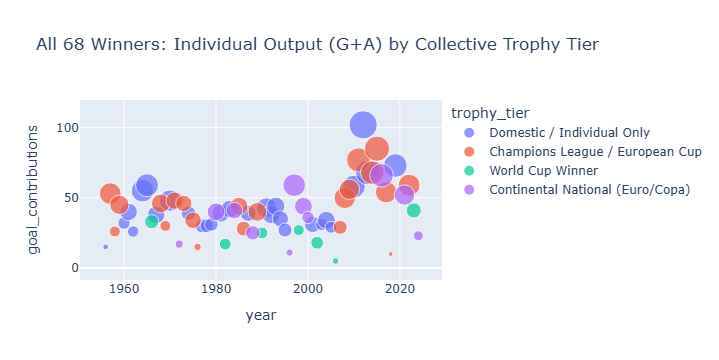

In [16]:
for tier, group in df_valid.groupby("trophy_tier"):
    print(f"\n==================== {tier.upper()} ({len(group)} vencedores) ====================")
    display(group[["year", "player", "club", "season_goals", "season_assists", "goal_contributions", "key_achievement"]])

fig1 = px.scatter(
    df_valid,
    x="year",
    y="goal_contributions",
    color="trophy_tier",
    size="season_goals",
    hover_data=["player", "club", "season_goals", "season_assists", "key_achievement"],
    title="All 68 Winners: Individual Output (G+A) by Collective Trophy Tier"
)
fig1.show()


==================== POSIÇÃO: DEFENDER (4 vencedores) ====================


,year,player,modern_country,club,age_at_win,season_goals,season_assists,trophy_tier
16,1972,Franz Beckenbauer,Germany,Bayern Munich,27.0,6.0,11.0,Continental National (Euro/Copa)
20,1976,Franz Beckenbauer,Germany,Bayern Munich,31.0,5.0,10.0,Champions League / European Cup
40,1996,Matthias Sammer,Germany,Borussia Dortmund,29.0,5.0,6.0,Continental National (Euro/Copa)
50,2006,Fabio Cannavaro,Italy,Juventus / Real Madrid,33.0,4.0,1.0,World Cup Winner



==================== POSIÇÃO: FORWARD (45 vencedores) ====================


,year,player,modern_country,club,age_at_win,season_goals,season_assists,trophy_tier
0,1956,Stanley Matthews,England,Blackpool,41.0,3.0,12.0,Domestic / Individual Only
1,1957,Alfredo Di Stéfano,Spain,Real Madrid,31.0,43.0,10.0,Champions League / European Cup
3,1959,Alfredo Di Stéfano,Spain,Real Madrid,33.0,34.0,11.0,Champions League / European Cup
5,1961,Omar Sívori,Italy,Juventus,26.0,28.0,12.0,Domestic / Individual Only
8,1964,Denis Law,Scotland,Manchester United,24.0,46.0,9.0,Domestic / Individual Only
9,1965,Eusébio,Portugal,Benfica,23.0,48.0,11.0,Domestic / Individual Only
11,1967,Flórián Albert,Hungary,Ferencváros,26.0,28.0,10.0,Domestic / Individual Only
12,1968,George Best,Northern Ireland,Manchester United,22.0,32.0,14.0,Champions League / European Cup
14,1970,Gerd Müller,Germany,Bayern Munich,25.0,42.0,6.0,Domestic / Individual Only
15,1971,Johan Cruyff,Netherlands,Ajax,24.0,27.0,21.0,Champions League / European Cup



==================== POSIÇÃO: GOALKEEPER (1 vencedores) ====================


,year,player,modern_country,club,age_at_win,season_goals,season_assists,trophy_tier
7,1963,Lev Yashin,Soviet Union,Dynamo Moscow,34.0,0.0,0.0,Domestic / Individual Only



==================== POSIÇÃO: MIDFIELDER (18 vencedores) ====================


,year,player,modern_country,club,age_at_win,season_goals,season_assists,trophy_tier
2,1958,Raymond Kopa,France,Real Madrid,27.0,11.0,15.0,Champions League / European Cup
4,1960,Luis Suárez,Spain,Barcelona,25.0,14.0,18.0,Domestic / Individual Only
6,1962,Josef Masopust,Czech Republic,Dukla Prague,31.0,12.0,14.0,Domestic / Individual Only
10,1966,Bobby Charlton,England,Manchester United,29.0,18.0,15.0,World Cup Winner
13,1969,Gianni Rivera,Italy,AC Milan,26.0,11.0,19.0,Champions League / European Cup
27,1983,Michel Platini,France,Juventus,28.0,28.0,14.0,Domestic / Individual Only
28,1984,Michel Platini,France,Juventus,29.0,25.0,16.0,Continental National (Euro/Copa)
29,1985,Michel Platini,France,Juventus,30.0,29.0,15.0,Champions League / European Cup
31,1987,Ruud Gullit,Netherlands,PSV / AC Milan,25.0,24.0,15.0,Domestic / Individual Only
34,1990,Lothar Matthäus,Germany,Inter Milan,29.0,13.0,12.0,World Cup Winner


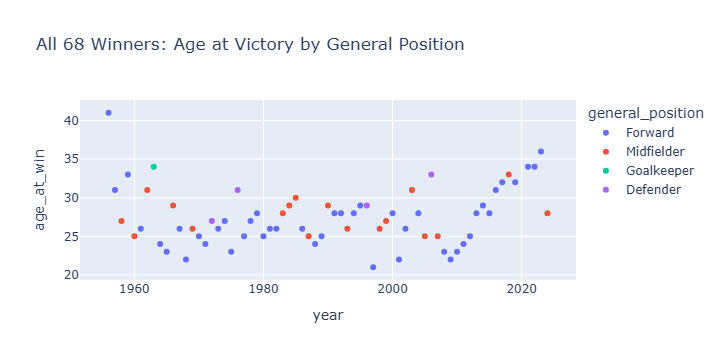

In [17]:
for pos, group in df_valid.groupby("general_position"):
    print(f"\n==================== POSIÇÃO: {pos.upper()} ({len(group)} vencedores) ====================")
    display(group[["year", "player", "modern_country", "club", "age_at_win", "season_goals", "season_assists", "trophy_tier"]])

fig2 = px.scatter(
    df_valid,
    x="year",
    y="age_at_win",
    color="general_position",
    hover_data=["player", "modern_country", "club", "season_goals", "season_assists"],
    title="All 68 Winners: Age at Victory by General Position"
)
fig2.show()

,Total_Awards,Unique_Players,Players_List,Years
modern_country,,,,
Argentina,8,1,Lionel Messi,"2009, 2010, 2011, 2012, 2015, 2019, 2021, 2023"
France,7,5,"Raymond Kopa, Michel Platini, Jean-Pierre Papi...","1958, 1983, 1984, 1985, 1991, 1998, 2022"
Germany,7,5,"Gerd Müller, Franz Beckenbauer, Karl-Heinz Rum...","1970, 1972, 1976, 1980, 1981, 1990, 1996"
Portugal,7,3,"Eusébio, Luís Figo, Cristiano Ronaldo","1965, 2000, 2008, 2013, 2014, 2016, 2017"
Netherlands,7,3,"Johan Cruyff, Ruud Gullit, Marco van Basten","1971, 1973, 1974, 1987, 1988, 1989, 1992"
England,5,4,"Stanley Matthews, Bobby Charlton, Kevin Keegan...","1956, 1966, 1978, 1979, 2001"
Brazil,5,4,"Ronaldo, Rivaldo, Ronaldinho, Kaká","1997, 1999, 2002, 2005, 2007"
Italy,5,5,"Omar Sívori, Gianni Rivera, Paolo Rossi, Rober...","1961, 1969, 1982, 1993, 2006"
Spain,4,3,"Alfredo Di Stéfano, Luis Suárez, Rodri","1957, 1959, 1960, 2024"


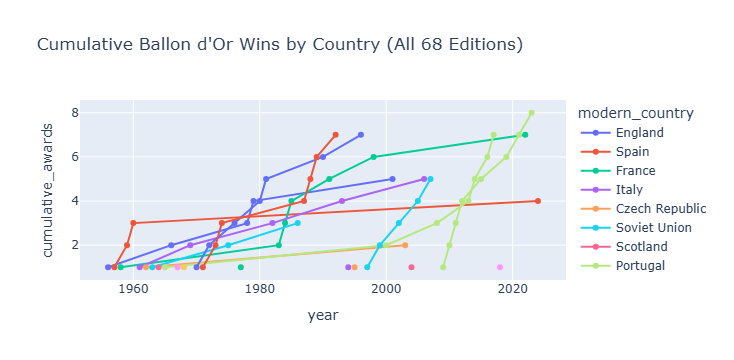

In [18]:
country_ranking = (
    df_valid.groupby("modern_country")
    .agg(
        Total_Awards=("year", "count"),
        Unique_Players=("player", "nunique"),
        Players_List=("player", lambda x: ", ".join(x.unique())),
        Years=("year", lambda x: ", ".join(x.astype(str)))
    )
    .sort_values(by="Total_Awards", ascending=False)
)
display(country_ranking)

df_sorted = df_valid.sort_values("year").copy()
df_sorted["cumulative_awards"] = df_sorted.groupby("modern_country").cumcount() + 1

fig3 = px.line(
    df_sorted,
    x="year",
    y="cumulative_awards",
    color="modern_country",
    markers=True,
    hover_data=["player", "club", "season_goals", "season_assists"],
    title="Cumulative Ballon d'Or Wins by Country (All 68 Editions)"
)
fig3.show()

,Editions,Years_Range,Avg_Goals,Avg_Assists,Avg_G_Plus_A,Winners
award_era,,,,,,
European Players Only,39,1956–1994,23.3,12.0,35.3,"Stanley Matthews, Alfredo Di Stéfano, Raymond ..."
European Club Players,12,1995–2006,18.6,10.8,29.3,"George Weah, Matthias Sammer, Ronaldo, Zinédin..."
Global Era,3,2007–2009,32.7,12.3,45.0,"Kaká, Cristiano Ronaldo, Lionel Messi"
FIFA Ballon d'Or,6,2010–2015,56.2,20.2,76.3,"Lionel Messi, Lionel Messi, Lionel Messi, Cris..."
France Football Return,5,2016–2021,36.8,14.2,51.0,"Cristiano Ronaldo, Cristiano Ronaldo, Luka Mod..."
Season-Based Format,2,2022–2023,32.5,17.5,50.0,"Karim Benzema, Lionel Messi"
Season-Based Format (UEFA),1,2024–2024,9.0,14.0,23.0,Rodri


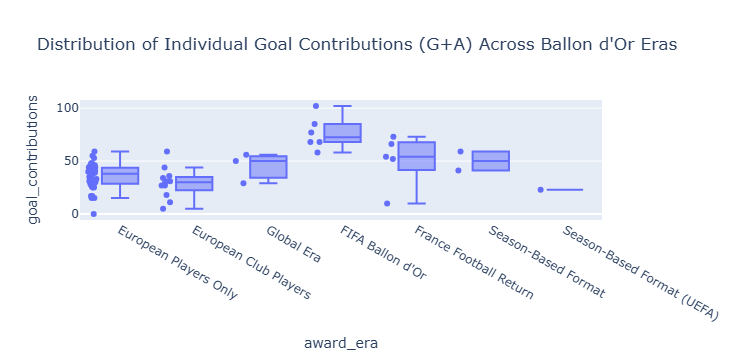

In [19]:
era_summary = (
    df_valid.groupby("award_era", sort=False)
    .agg(
        Editions=("year", "count"),
        Years_Range=("year", lambda x: f"{x.min()}–{x.max()}"),
        Avg_Goals=("season_goals", "mean"),
        Avg_Assists=("season_assists", "mean"),
        Avg_G_Plus_A=("goal_contributions", "mean"),
        Winners=("player", lambda x: ", ".join(x))
    )
    .round(1)
)
display(era_summary)

fig4 = px.box(
    df_valid,
    x="award_era",
    y="goal_contributions",
    points="all",
    hover_data=["year", "player", "season_goals", "season_assists", "trophy_tier"],
    title="Distribution of Individual Goal Contributions (G+A) Across Ballon d'Or Eras"
)
fig4.show()

In [20]:
player_ranking = (
    df_valid.groupby(["player", "modern_country", "general_position"])
    .agg(
        Ballons_dOr=("year", "count"),
        Years_Won=("year", lambda x: ", ".join(x.astype(str))),
        Avg_Goals=("season_goals", "mean"),
        Avg_Assists=("season_assists", "mean"),
        Peak_G_Plus_A=("goal_contributions", "max")
    )
    .round(1)
    .sort_values(by=["Ballons_dOr", "Peak_G_Plus_A"], ascending=False)
)
display(player_ranking)

,,,Ballons_dOr,Years_Won,Avg_Goals,Avg_Assists,Peak_G_Plus_A
player,modern_country,general_position,,,,,
Lionel Messi,Argentina,Forward,8,"2009, 2010, 2011, 2012, 2015, 2019, 2021, 2023",47.4,20.6,102.0
Cristiano Ronaldo,Portugal,Forward,5,"2008, 2013, 2014, 2016, 2017",48.2,13.0,68.0
Johan Cruyff,Netherlands,Forward,3,"1971, 1973, 1974",23.3,21.0,48.0
Michel Platini,France,Midfielder,3,"1983, 1984, 1985",27.3,15.0,44.0
Marco van Basten,Netherlands,Forward,3,"1988, 1989, 1992",26.7,7.7,40.0
Ronaldo,Brazil,Forward,2,"1997, 2002",31.0,7.5,59.0
Alfredo Di Stéfano,Spain,Forward,2,"1957, 1959",38.5,10.5,53.0
Karl-Heinz Rummenigge,Germany,Forward,2,"1980, 1981",29.0,10.5,40.0
Kevin Keegan,England,Forward,2,"1978, 1979",17.0,13.5,31.0


,Total_Awards,Players,Years
club,,,
Barcelona,11,"Luis Suárez, Johan Cruyff, Hristo Stoichkov, R...","1960, 1974, 1994, 1999, 2005, 2009, 2010, 2011..."
Real Madrid,9,"Alfredo Di Stéfano, Raymond Kopa, Cristiano Ro...","1957, 1958, 1959, 2013, 2014, 2016, 2017, 2018..."
Juventus,8,"Omar Sívori, Paolo Rossi, Michel Platini, Robe...","1961, 1982, 1983, 1984, 1985, 1993, 1998, 2003"
AC Milan,6,"Gianni Rivera, Marco van Basten, Andriy Shevch...","1969, 1988, 1989, 1992, 2004, 2007"
Bayern Munich,5,"Gerd Müller, Franz Beckenbauer, Karl-Heinz Rum...","1970, 1972, 1976, 1980, 1981"
Manchester United,4,"Denis Law, Bobby Charlton, George Best, Cristi...","1964, 1966, 1968, 2008"
Dynamo Kyiv,2,"Oleg Blokhin, Igor Belanov","1975, 1986"
Hamburger SV,2,Kevin Keegan,"1978, 1979"
Barcelona / Real Madrid,1,Luís Figo,2000


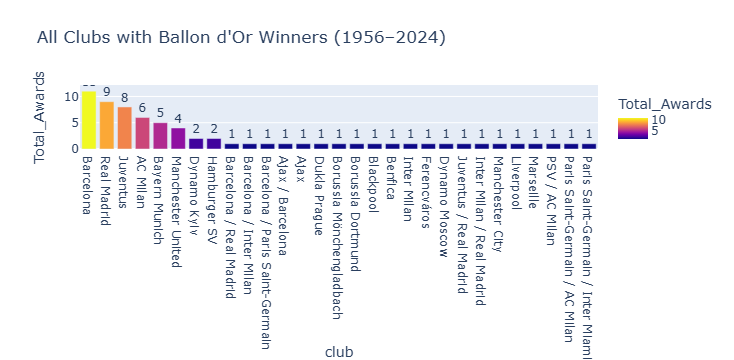

In [21]:
club_ranking = (
    df_valid.groupby("club")
    .agg(
        Total_Awards=("year", "count"),
        Players=("player", lambda x: ", ".join(x.unique())),
        Years=("year", lambda x: ", ".join(x.astype(str)))
    )
    .sort_values(by="Total_Awards", ascending=False)
)
display(club_ranking)

fig5 = px.bar(
    club_ranking.reset_index(),
    x="club",
    y="Total_Awards",
    text="Total_Awards",
    hover_data=["Players", "Years"],
    title="All Clubs with Ballon d'Or Winners (1956–2024)",
    color="Total_Awards"
)
fig5.update_traces(textposition="outside")
fig5.show()